In [36]:
"""
Responsible for XGBoost YI-PENG 3 case validation, SHAP, MDI values

Refactored with assistance from Anthropic Claude (Claude Sonnet 5.5).
Changes made:
- Removed the shebang, coding line, Jupyter/nbconvert cell markers, and empty cells.
- Removed the unused import sklearn.metrics.mean_pinball_loss and moved the
  mid-file `import shap` to the top.
- Converted notebook cell output expressions (PI coverage means, false-positive
  rate, anomaly-free fraction, MDI tables, hard-coded MDI ratios) into
  explicit, labelled print() calls.
- Replaced plt.show() with plt.close(); the two bare exploratory line plots
  are now saved as figures instead of being displayed.
- All figures are saved to ../images/ (the MDI and SHAP figures were
  previously saved to the current working directory).
- All data inputs are read from ../../output/data_yipeng3/qrf/.
- Loaded the val/test MMSI and day arrays once instead of in several cells.
- Dropped the duplicated best_hyper definition before the Delta DIF section
  (identical to the one before Delta COG).
- Consolidated the two duplicated NMR cells into one reusable function and
  the duplicated MDI table/plot code into one helper; call parameters are
  preserved.
- Removed stale comments (commented-out debug prints in the NMR code).
- Fixed the title of the lower-bound SHAP plot, which said "upper".
- Preserved the original modeling logic and parameter choices.
"""

import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from pathlib import Path
from datetime import datetime, timedelta

plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

IMAGE_DIR = Path("../images")
DATA_DIR = Path("../../output/data_yipeng3/qrf")

IMAGE_DIR.mkdir(parents=True, exist_ok=True)


X_train = np.load(DATA_DIR / 'X_train.npy')
y_train = np.load(DATA_DIR / 'y_train.npy')
X_test = np.load(DATA_DIR / 'X_test.npy')
y_test = np.load(DATA_DIR / 'y_test.npy')
X_val = np.load(DATA_DIR / 'X_val.npy')
y_val = np.load(DATA_DIR / 'y_val.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS * N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS * N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS * N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS * N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS * N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS * N_INP_FEATS))

yipeng3_y = np.load(
    DATA_DIR / 'yipeng3_y.npy',
    allow_pickle=True
).reshape((-1, 5 * 3))
yipeng3_x = np.load(
    DATA_DIR / 'yipeng3_x.npy',
    allow_pickle=True
).reshape((-1, 5 * 20))

val_mmsis = np.load(DATA_DIR / 'val-mmsis.npy', allow_pickle=True)
val_days = np.load(DATA_DIR / 'val-days.npy', allow_pickle=True)
test_mmsis = np.load(DATA_DIR / 'test-mmsis.npy', allow_pickle=True)
test_days = np.load(DATA_DIR / 'test-days.npy', allow_pickle=True)


# ## Delta COG

best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 0.6
}

var_num = 0

model_low = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.025,
    device='gpu',
    **best_hyper
)

model_high = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.975,
    device='gpu',
    **best_hyper
)

model_low.fit(X_train, y_train[:, var_num])
model_high.fit(X_train, y_train[:, var_num])

yipeng3_low = model_low.predict(yipeng3_x)
yipeng3_high = model_high.predict(yipeng3_x)

y_low = model_low.predict(X_val)
y_high = model_high.predict(X_val)

in_pi_mask = (y_val[:, var_num] > y_low) & (y_val[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [in_pi_mask[ix]]
    else:
        group_results[(mmsi, day)].append(in_pi_mask[ix])

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means
    })

df = pd.DataFrame(df)
print('Delta COG:', np.quantile(df['delta_cog'], 0.05))

print(
    'YI-PENG 3 Delta COG',
    np.mean(
        (yipeng3_y[:, var_num] < yipeng3_high[:]) &
        (yipeng3_y[:, var_num] > yipeng3_low[:])
    )
)

Delta COG: 0.8531512605042016
YI-PENG 3 Delta COG 0.9359605911330049


In [38]:

best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 1.0
}

var_num = 2

model_low = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.025,
    device='gpu',
    **best_hyper
)

model_high = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.975,
    device='gpu',
    **best_hyper
)

model_low.fit(X_train, y_train[:, var_num])
model_high.fit(X_train, y_train[:, var_num])

yipeng3_low = model_low.predict(yipeng3_x)
yipeng3_high = model_high.predict(yipeng3_x)

y_low = model_low.predict(X_val)
y_high = model_high.predict(X_val)

in_pi_mask = (y_val[:, var_num] > y_low) & (y_val[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [in_pi_mask[ix]]
    else:
        group_results[(mmsi, day)].append(in_pi_mask[ix])

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means
    })

df = pd.DataFrame(df)
thresh_dif = np.quantile(df['delta_cog'], 0.05)
print('DIF:', thresh_dif)

print(
    'YI-PENG 3 DIF (first 75 steps)',
    np.mean(
        (yipeng3_y[:75, var_num] < yipeng3_high[:75]) &
        (yipeng3_y[:75, var_num] > yipeng3_low[:75])
    )
)


# False positive rate on the test set (DIF)
y_low = model_low.predict(X_test)
y_high = model_high.predict(X_test)

in_pi_mask = (y_test[:, var_num] > y_low) & (y_test[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(test_mmsis, test_days)):
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [in_pi_mask[ix]]
    else:
        group_results[(mmsi, day)].append(in_pi_mask[ix])

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'dif': means
    })

df = pd.DataFrame(df)
print('FPR for DIF is', np.mean(df['dif'] < thresh_dif))


DIF: 0.8639328063241107
YI-PENG 3 DIF (first 75 steps) 0.84
FPR for DIF is 0.06635071090047394


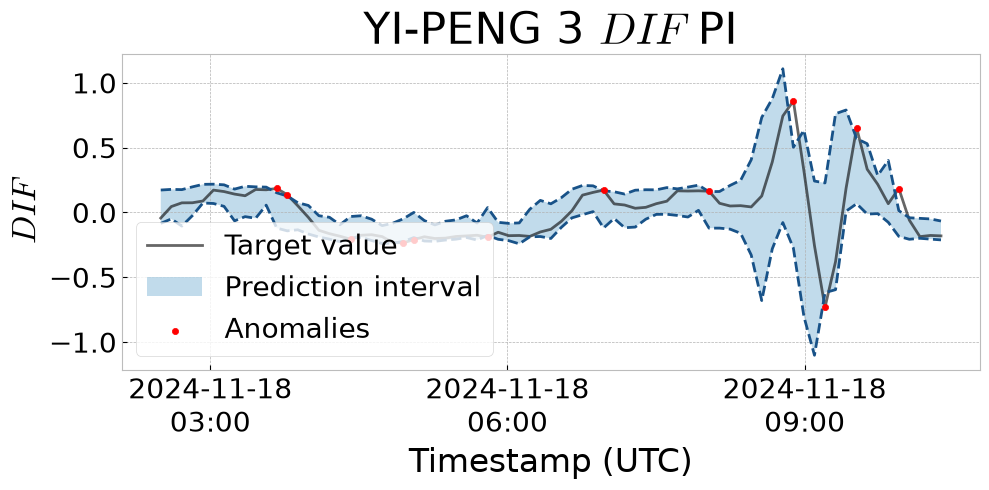

In [ ]:
timestamps_yipeng3 = pd.date_range(
    start=datetime(2024, 11, 18, 2, 30),
    end=datetime(2024, 11, 19, 0, 0),
    periods=yipeng3_y.shape[0]
)

y_flat = yipeng3_y[:75, 2]
y_low = yipeng3_low[:75]
y_high = yipeng3_high[:75]
timestamps_yipeng3 = list(timestamps_yipeng3)[:75]

anomalies_x = []
anomalies_y = []
for i in range(y_flat.shape[0]):
    if y_flat[i] < y_low[i]:
        anomalies_x.append(timestamps_yipeng3[i])
        anomalies_y.append(y_flat[i])

    elif y_flat[i] > y_high[i]:
        anomalies_x.append(timestamps_yipeng3[i])
        anomalies_y.append(y_flat[i])

fig = plt.figure(figsize=(10,6))

plt.plot(
    timestamps_yipeng3,
    y_flat,
    label="Target value",
    color='black',
    alpha=0.6
)
plt.plot(timestamps_yipeng3, y_low, color='#185288', linestyle='--')
plt.plot(timestamps_yipeng3, y_high, color="#185288", linestyle='--')

ticks = [
    datetime(2024, 11, 18, 0, 0) + timedelta(hours=x)
    for x in range(0, 30, 3)
]
labels = [tick.strftime('%Y-%m-%d\n%H:%M') for tick in ticks]
plt.xticks(
    ticks=ticks,
    labels=labels
)
plt.tick_params(axis='both', which='both', labelsize=20)

plt.xlabel('Timestamp (UTC)', size=24)
plt.ylabel(r'$DIF$', size=24)
plt.title(r'YI-PENG 3 $DIF$ PI', size=32)

plt.fill_between(
    x=timestamps_yipeng3,
    y1=y_low,
    y2=y_high,
    alpha=0.3,
    label='Prediction interval'
)
plt.scatter(
    anomalies_x,
    anomalies_y,
    color='red',
    s=20,
    zorder=5,
    label='Anomalies'
)
plt.legend(fontsize=20)

plt.tight_layout()
# plt.savefig(IMAGE_DIR / 'dif-xgboost-yipeng3.pdf', format='pdf', bbox_inches='tight')
# plt.close(fig)

plt.show()
